## Create the dataset

We will generate data from a known function:
y = sin(1.5*pi*x) + noise

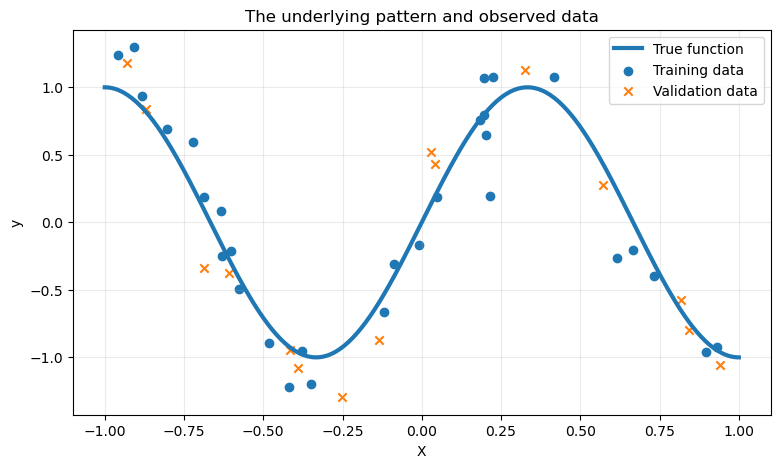

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

# The underlying relationship we want the model to learn
def true_function(x):
    return np.sin(1.5 * np.pi * x)

# Generate observed data
n_samples = 60
X = np.random.uniform(-1, 1, size=(n_samples, 1))
y = true_function(X) + np.random.normal(
    loc=0, scale=0.25, size=(n_samples, 1)
)

# Split into training, validation, and test sets
indices = np.random.permutation(n_samples)

train_idx = indices[:30]
val_idx = indices[30:45]
test_idx = indices[45:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Convert NumPy arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# A smooth grid for drawing prediction curves
X_grid = np.linspace(-1, 1, 300).reshape(-1, 1)
y_true_grid = true_function(X_grid)

plt.figure(figsize=(9, 5))
plt.plot(X_grid, y_true_grid, label="True function", linewidth=3)
plt.scatter(
    X_train.numpy(), y_train.numpy(),
    label="Training data", marker="o"
)
plt.scatter(
    X_val.numpy(), y_val.numpy(),
    label="Validation data", marker="x"
)
plt.xlabel("X")
plt.ylabel("y")
plt.title("The underlying pattern and observed data")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Define a flexible neural network

In [2]:
class RegressionNN(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()

        layers = []
        input_size = 1

        for hidden_size in hidden_sizes:
            layers.append(
                nn.Linear(input_size, hidden_size)
            )
            layers.append(nn.Tanh())

            input_size = hidden_size

        # One output neuron because this is regression
        layers.append(nn.Linear(input_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

## The training function

In [3]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=300,
    learning_rate=0.01,
    weight_decay=0.0
):
    loss_fn = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()

        predictions = model(X_train)
        train_loss = loss_fn(predictions, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Evaluate validation loss without updating weights
        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val)
            val_loss = loss_fn(val_predictions, y_val)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

    return train_losses, val_losses

## Train three networks

In [4]:
configs = {
    "Too simple: 2 neurons": [2],
    "Moderate: 16 neurons": [16],
    "Large Model: 64 x 64 x 64 x 64": [64, 64, 64, 64]
}

models = {}
histories = {}

for name, hidden_sizes in configs.items():
    torch.manual_seed(42)

    model = RegressionNN(hidden_sizes)

    train_losses, val_losses = train_model(
        model,
        X_train, y_train,
        X_val, y_val,
        epochs=500,
        learning_rate=0.01
    )

    models[name] = model
    histories[name] = (train_losses, val_losses)

## Visualize the fitted curves

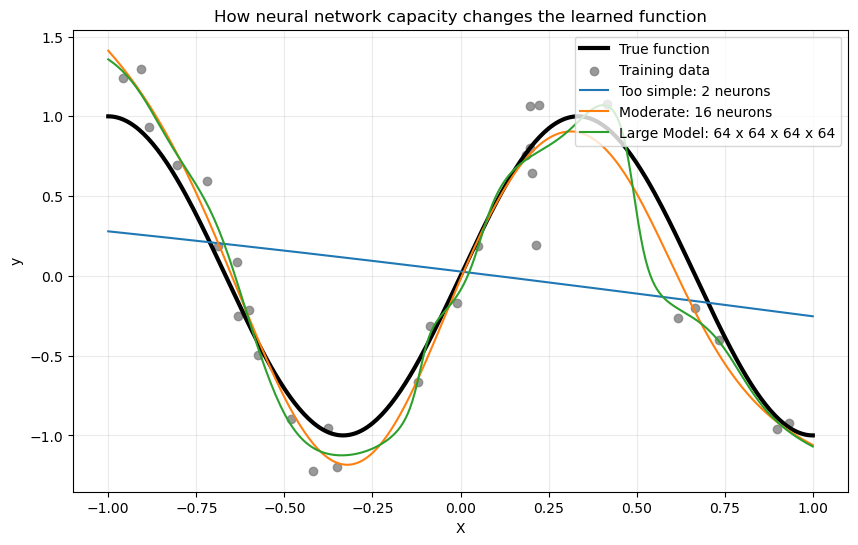

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(
    X_grid, y_true_grid,
    color="black", linewidth=3, label="True function"
)

plt.scatter(
    X_train.numpy(), y_train.numpy(),
    color="gray", alpha=0.8, label="Training data"
)

with torch.no_grad():
    for name, model in models.items():
        model.eval()

        X_grid_tensor = torch.tensor(
            X_grid, dtype=torch.float32
        )
        predictions = model(X_grid_tensor).numpy()

        plt.plot(X_grid, predictions, label=name)

plt.xlabel("X")
plt.ylabel("y")
plt.title("How neural network capacity changes the learned function")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Plot training and validation loss

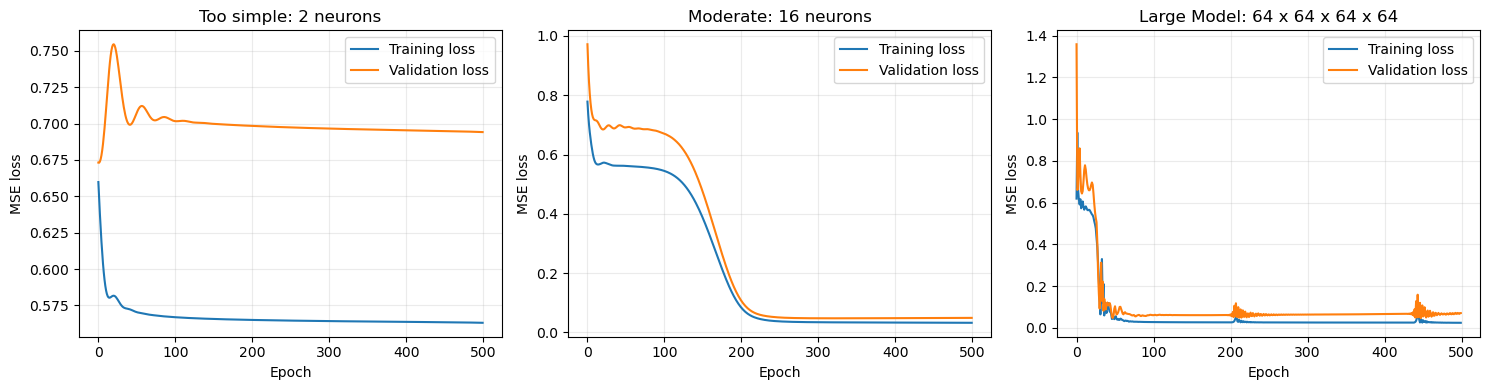

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, (train_losses, val_losses)) in zip(
    axes, histories.items()
):
    ax.plot(train_losses, label="Training loss")
    ax.plot(val_losses, label="Validation loss")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Hyperparameter tuning

In [ ]:
import pandas as pd

search_space = [
    # Architecture, learning rate, weight decay
    ([2],       0.01, 0.0),
    ([8],       0.01, 0.0),
    ([16],      0.01, 0.0),
    ([64],      0.01, 0.0),
    ([16, 16],  0.01, 0.0),
    ([64, 64],  0.01, 0.0),
    ([16],      0.001, 0.0),
    ([16],      0.01, 0.01),
]

results = []
candidate_models = []

for hidden_sizes, lr, wd in search_space:
    torch.manual_seed(42)

    model = RegressionNN(hidden_sizes)

    train_losses, val_losses = train_model(
        model,
        X_train, y_train,
        X_val, y_val,
        epochs=500,
        learning_rate=lr,
        weight_decay=wd
    )

    # Use the final validation loss for this simple demonstration
    results.append({
        "hidden_layers": str(hidden_sizes),
        "learning_rate": lr,
        "weight_decay": wd,
        "train_mse": train_losses[-1],
        "validation_mse": val_losses[-1]
    })

    candidate_models.append(model)

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("validation_mse")

print(results_df.to_string(index=False))